# Аналитика удовлетворённости клиентов ресторанов

[Источник датасета](https://www.kaggle.com/datasets/rabieelkharoua/predict-restaurant-customer-satisfaction-dataset)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 95
colors = ['#5DADE2', '#48C9B0']

In [2]:
df = pd.read_csv('restaurant_customer_satisfaction.csv')

In [3]:
df

,CustomerID,Age,Gender,Income,VisitFrequency,AverageSpend,PreferredCuisine,TimeOfVisit,GroupSize,DiningOccasion,MealType,OnlineReservation,DeliveryOrder,LoyaltyProgramMember,WaitTime,ServiceRating,FoodRating,AmbianceRating,HighSatisfaction
0,654,35,Male,83380,Weekly,27.829142,Chinese,Breakfast,3,Business,Takeaway,0,1,1,43.523929,2,5,4,0
1,655,19,Male,43623,Rarely,115.408622,American,Dinner,1,Casual,Dine-in,0,0,0,57.524294,5,5,3,0
2,656,41,Female,83737,Weekly,106.693771,American,Dinner,6,Celebration,Dine-in,0,1,0,48.682623,3,4,5,0
3,657,43,Male,96768,Rarely,43.508508,Indian,Lunch,1,Celebration,Dine-in,0,0,0,7.552993,4,5,1,0
4,658,55,Female,67937,Monthly,148.084627,Chinese,Breakfast,1,Business,Takeaway,0,0,1,37.789041,2,3,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,2149,39,Male,114857,Monthly,163.015254,American,Lunch,2,Business,Dine-in,0,1,1,7.206275,1,2,1,0
1496,2150,37,Female,133506,Weekly,190.991911,Italian,Lunch,4,Casual,Takeaway,0,0,0,37.863952,5,2,2,0
1497,2151,46,Male,119159,Monthly,150.088604,American,Lunch,4,Casual,Dine-in,0,1,0,3.925785,3,3,3,1
1498,2152,24,Male,27970,Weekly,196.363626,Italian,Dinner,6,Casual,Dine-in,1,1,0,24.228038,2,2,4,1


## Гипотезы

- **H1.** Средняя оценка еды различается у клиентов с разными предпочтениями по типу кухни.
- **H2.** Посетители, приходящие большими компаниями, ниже оценивают атмосферу ресторана.
- **H3.** Клиенты, посещающие ресторан для деловых встреч, выше оценивают обслуживание.
- **H4.** Пользователи доставки ниже оценивают еду, чем клиенты, не использующие доставку.
- **H5.** Частота посещений связана со средним чеком и долей клиентов с высокой удовлетворённостью.
- **H6.** Молодые клиенты чаще используют онлайн-бронирование и доставку. Дополнительно покажем число и долю клиентов в каждой возрастной когорте.
- **H7.** Среди клиентов с низкими оценками еды, сервиса и атмосферы участники программы лояльности чаще сохраняют высокую общую удовлетворённость.

In [4]:
def finish_plot(ax, title, xlabel, ylabel, fmt='%.2f', legend=False):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    for bars in ax.containers:
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9)
    if legend:
        ax.figure.legend(loc='lower center', ncol=2, fontsize=8, frameon=False)
    ax.figure.tight_layout(rect=(0, 0.11 if legend else 0, 1, 1))
    plt.show()


def bar_chart(values, title, xlabel, ylabel, fmt='%.2f', rotation=0, size=(6.5, 3.6)):
    grouped = values.ndim == 2
    ax = values.plot.bar(figsize=size, rot=rotation, color=colors if grouped else colors[0], legend=False)
    ax.set_ylim(0, values.to_numpy().max() * 1.18)
    finish_plot(ax, title, xlabel, ylabel, fmt, legend=grouped)

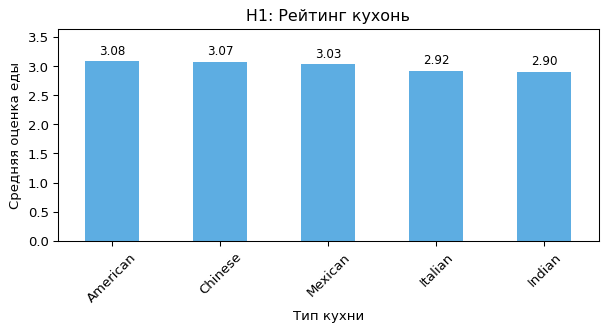

In [5]:
# H1. Оценки еды по предпочтительной кухне
food = df.groupby('PreferredCuisine')['FoodRating'].mean().sort_values(ascending=False)
bar_chart(food, 'H1: Рейтинг кухонь', 'Тип кухни', 'Средняя оценка еды', rotation=45)

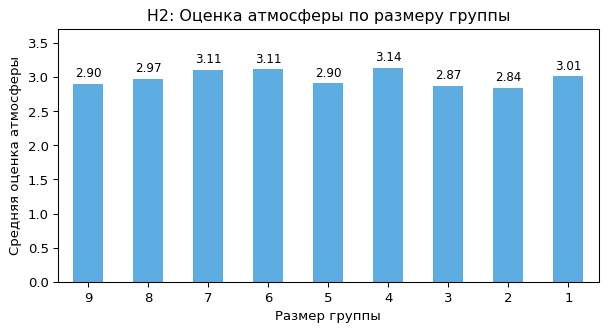

In [6]:
# H2. Атмосфера по размеру компании
atmosphere = df.groupby('GroupSize')['AmbianceRating'].mean().sort_index(ascending=False)
bar_chart(atmosphere, 'H2: Оценка атмосферы по размеру группы', 'Размер группы', 'Средняя оценка атмосферы')

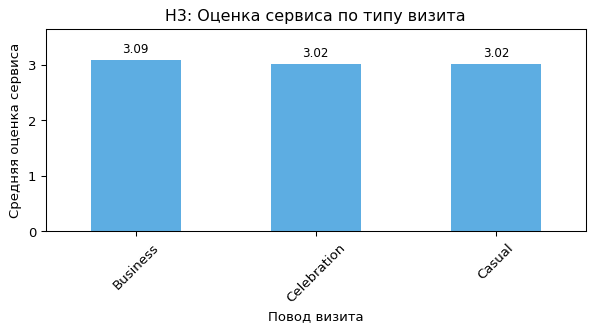

In [7]:
# H3. Сервис по поводу визита
service = df.groupby('DiningOccasion')['ServiceRating'].mean().sort_values(ascending=False)
bar_chart(service, 'H3: Оценка сервиса по типу визита', 'Повод визита', 'Средняя оценка сервиса', rotation=45)

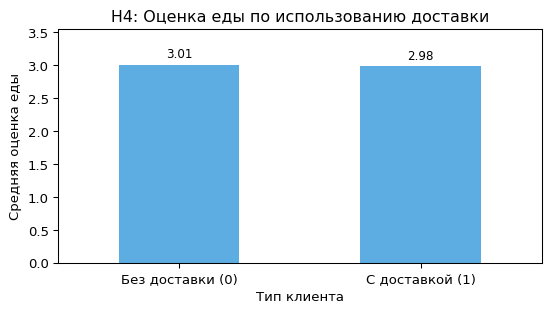

In [8]:
# H4. Оценки еды с доставкой и без неё
food = df.groupby('DeliveryOrder')['FoodRating'].mean().rename(index={0: 'Без доставки (0)', 1: 'С доставкой (1)'})
bar_chart(food, 'H4: Оценка еды по использованию доставки', 'Тип клиента', 'Средняя оценка еды', size=(5.9, 3.4))

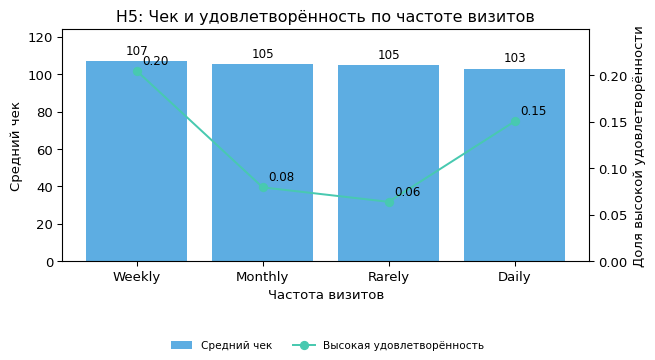

In [9]:
# H5. Чек и удовлетворённость по частоте визитов
metrics = ['AverageSpend', 'HighSatisfaction']
visits = df.dropna(subset=metrics).groupby('VisitFrequency')[metrics].mean().sort_values('AverageSpend', ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(visits.index, visits['AverageSpend'], color=colors[0], label='Средний чек')
ax.set_ylim(0, visits['AverageSpend'].max() * 1.16)

right = ax.twinx()
right.plot(visits.index, visits['HighSatisfaction'], marker='o', color=colors[1], label='Высокая удовлетворённость')
right.set(ylabel='Доля высокой удовлетворённости', ylim=(0, visits['HighSatisfaction'].max() + 0.045))
for i, value in enumerate(visits['HighSatisfaction']):
    right.annotate(f'{value:.2f}', (i, value), xytext=(14, 5), textcoords='offset points', ha='center', fontsize=9)
finish_plot(ax, 'H5: Чек и удовлетворённость по частоте визитов', 'Частота визитов', 'Средний чек', '%.0f', legend=True)

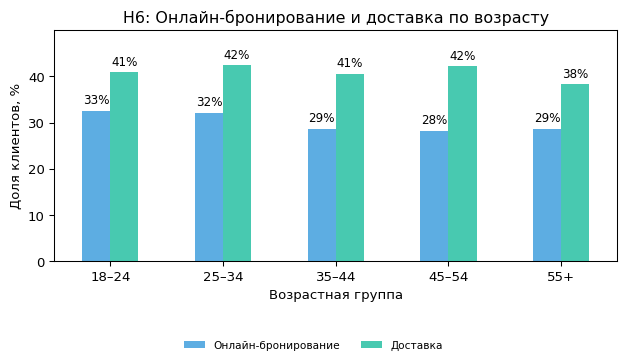

,Число клиентов,"Доля всех клиентов, %"
Возрастная когорта,,
18–24,203,13.53
25–34,255,17.00
35–44,311,20.73
45–54,287,19.13
55+,444,29.60


In [10]:
# H6. Бронирование и доставка по возрасту
age_groups = pd.cut(df['Age'], [18, 25, 35, 45, 55, 70], labels=['18–24', '25–34', '35–44', '45–54', '55+'], right=False)
services = df[['OnlineReservation', 'DeliveryOrder']].dropna().groupby(age_groups, observed=False).mean().mul(100).round(2)
services = services.rename(columns={'OnlineReservation': 'Онлайн-бронирование', 'DeliveryOrder': 'Доставка'})
bar_chart(services, 'H6: Онлайн-бронирование и доставка по возрасту', 'Возрастная группа', 'Доля клиентов, %', '%.0f%%', size=(6.7, 3.8))

counts = age_groups.value_counts(sort=False)
cohort_distribution = pd.DataFrame({'Число клиентов': counts, 'Доля всех клиентов, %': (counts / len(df) * 100).round(2)})
cohort_distribution.rename_axis('Возрастная когорта')

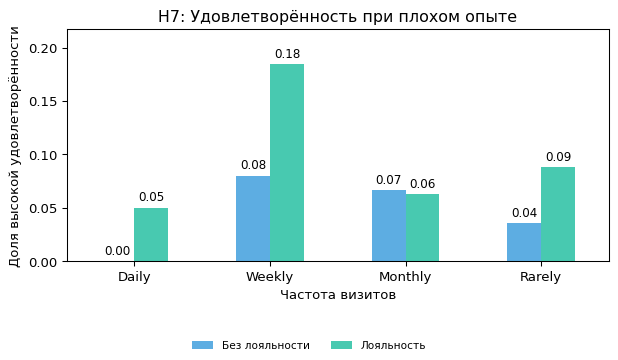

In [11]:
# H7. Удовлетворённость при плохом опыте
experience = df[['ServiceRating', 'FoodRating', 'AmbianceRating']].mean(axis=1, skipna=False)
loyalty = df.loc[experience <= 2.5].groupby(['VisitFrequency', 'LoyaltyProgramMember'])['HighSatisfaction'].mean().unstack()
loyalty = loyalty.reindex(index=['Daily', 'Weekly', 'Monthly', 'Rarely'], columns=[0, 1]).fillna(0)
loyalty = loyalty.rename(columns={0: 'Без лояльности', 1: 'Лояльность'})
bar_chart(loyalty, 'H7: Удовлетворённость при плохом опыте', 'Частота визитов', 'Доля высокой удовлетворённости', size=(6.7, 3.8))